In [1]:
import numpy as np
import pickle
import json
import os
import spectres
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from tqdm import tqdm

from POSEIDON.core import (create_star, create_planet, define_model,
                           make_atmosphere, compute_spectrum,
                           wl_grid_constant_R)
from POSEIDON.constants import R_J, M_J, R_Sun

## 1. Load Cleaned VMR Profiles

In [2]:
import pandas as pd

df_final_clean = pd.read_pickle("df_final.pkl")
df_final_clean = df_final_clean[~df_final_clean["is_flat"]].reset_index(drop=True)

# 'index' repeats across accounts — build a globally unique ID
df_final_clean["uid"] = (df_final_clean["account"] + "_" +
                          df_final_clean["index"].astype(str).str.zfill(4))

print(f"Total unique, clean VMR profiles to process: {len(df_final_clean)}")
print(df_final_clean.groupby("account").size())
print(df_final_clean[["uid", "account", "index", "T", "Rp_Rj",
                        "Mp_Mj", "Rstar_Rs", "log_Kzz"]].head())

Total unique, clean VMR profiles to process: 458
account
acct2      182
acct3      191
unknown     85
dtype: int64
          uid account  index            T     Rp_Rj      Mp_Mj  Rstar_Rs  \
0  acct2_0098   acct2     98   840.954267  1.344595   7.443698  0.905703   
1  acct2_0067   acct2     67   591.357930  1.901298   1.635848  1.143195   
2  acct2_0066   acct2     66  1213.248562  1.214805   1.771075  1.122038   
3  acct2_0072   acct2     72  1019.489505  1.202510  11.711646  1.424904   
4  acct2_0099   acct2     99  2263.304471  0.663275   5.398422  1.987718   

     log_Kzz  
0   6.641810  
1   4.250487  
2   4.140118  
3  10.073632  
4   7.218528  


## 2. Wavelength Grids, Opacities, Pressure Grid

In [3]:
# Wavelength grids
wl_min, wl_max, R_highres = 0.4, 10.0, 15000
wl_highres = wl_grid_constant_R(wl_min, wl_max, R_highres)
wl_binned  = np.load("free_chem_data/wl_binned.npy")

print(f"High-res grid : {len(wl_highres)} bins  ({wl_highres.min():.2f}–{wl_highres.max():.2f} μm)")
print(f"Binned grid   : {len(wl_binned)} bins  ({wl_binned.min():.2f}–{wl_binned.max():.2f} μm)")

# Opacity (load once — expensive)
OPAC_FILE = "opacities_created/opac_eq_chemistry.pickle"
with open(OPAC_FILE, "rb") as f:
    opac = pickle.load(f)
print("Opacities loaded.")

# Pressure grid — same as FRECKLL so no interpolation needed
N_layers    = 100
P           = np.logspace(2, -5, N_layers)   # 100 bar → 1e-5 bar
freckll_P   = P.copy()                        # identical grids

print(f"Pressure grid: {P.max():.1e} → {P.min():.1e} bar  ({N_layers} layers)")

High-res grid : 48283 bins  (0.40–10.00 μm)
Binned grid   : 52 bins  (0.55–7.28 μm)
Opacities loaded.
Pressure grid: 1.0e+02 → 1.0e-05 bar  (100 layers)


## 3. Helper Functions
All VMR values passed in **linear** scale — POSEIDON expects linear, not log10.

In [4]:
def build_X_input(h2o, ch4, co, co2, nh3):
    """
    Stack VMR profiles into X_input array for POSEIDON.
    All values must be in LINEAR scale (not log10).
    Order: [H2, He, H2O, CH4, CO, CO2, NH3]
    """
    h2_profile = np.full(N_layers, 0.83)   # bulk H2, linear
    he_profile = np.full(N_layers, 0.17)   # bulk He, linear
    return np.array([
        h2_profile,
        he_profile,
        h2o,    # linear VMR from FRECKLL
        ch4,
        co,
        co2,
        nh3,
    ])

## 4. Define POSEIDON Model and Star

In [5]:
bulk_species  = ["H2", "He"]
param_species = ["H2O", "CH4", "CO", "CO2", "NH3"]

model = define_model(
    "disequil_freckll_model",
    bulk_species,
    param_species,
    PT_profile = "file_read",
    X_profile  = "file_read",
)

# Sun-like star (same as Dataset A)
star = create_star(1.0 * R_Sun, 5778.0, 4.44, 0.0)

print("Model defined:", model["model_name"])
print("Star defined: R=1.0 Rsun, T=5778K")

Model defined: disequil_freckll_model
Star defined: R=1.0 Rsun, T=5778K


## 5. Single Spectrum Test
Verify the pipeline works on one profile before running the full loop.

Test profile: T=591K, Rp=1.90Rjup, Mp=1.64Mjup

X_input check (all should be linear, positive, not ~1.0):
  H2: min=8.300e-01, max=8.300e-01, nan=False, negative=False
  He: min=1.700e-01, max=1.700e-01, nan=False, negative=False
  H2O: min=6.090e-04, max=9.183e-04, nan=False, negative=False
  CH4: min=1.175e-04, max=4.197e-04, nan=False, negative=False
  CO: min=1.593e-17, max=2.952e-04, nan=False, negative=False
  CO2: min=5.472e-19, max=6.722e-06, nan=False, negative=False
  NH3: min=3.026e-09, max=1.239e-04, nan=False, negative=False

VMR sum at layer 0  (should be ~1.0): 1.0015
VMR sum at layer 50 (should be ~1.0): 1.0013

is_physical: True
Any NaN: False
Spectrum range: 0.038668 → 0.039432


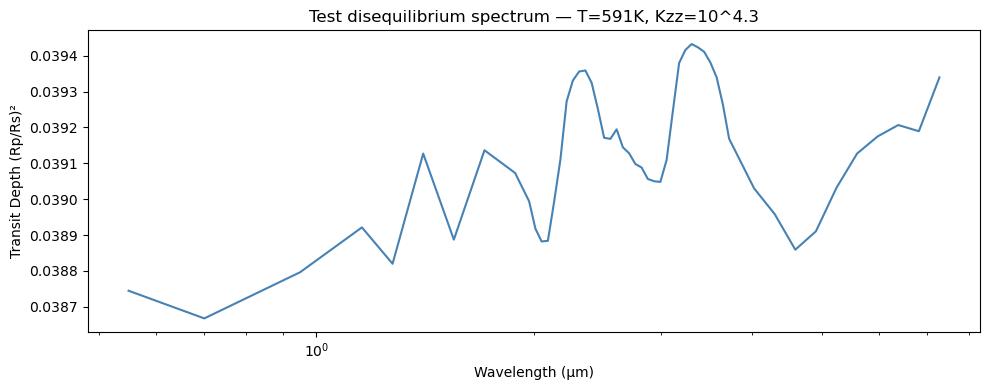

In [6]:
test_row  = df_final_clean.iloc[1]
test_data = np.load(test_row["path"])

T_test  = test_row["T"]
Rp_test = test_row["Rp_Rj"]
Mp_test = test_row["Mp_Mj"]

print(f"Test profile: T={T_test:.0f}K, Rp={Rp_test:.2f}Rjup, Mp={Mp_test:.2f}Mjup")

T_input = np.full(N_layers, T_test)
X_input = build_X_input(test_data["h2o"], test_data["ch4"],
                         test_data["co"],  test_data["co2"], test_data["nh3"])

# Verify X_input values
species_names = ["H2", "He", "H2O", "CH4", "CO", "CO2", "NH3"]
print("\nX_input check (all should be linear, positive, not ~1.0):")
for i, name in enumerate(species_names):
    v = X_input[i]
    print(f"  {name}: min={v.min():.3e}, max={v.max():.3e}, "
          f"nan={np.any(np.isnan(v))}, negative={np.any(v < 0)}")

print(f"\nVMR sum at layer 0  (should be ~1.0): {X_input[:, 0].sum():.4f}")
print(f"VMR sum at layer 50 (should be ~1.0): {X_input[:, 50].sum():.4f}")

# Build atmosphere
R_p    = Rp_test * R_J
M_p    = Mp_test * M_J
planet = create_planet("freckll_planet", R_p, mass=M_p, T_eq=T_test)
P_ref  = 10.0

atmosphere = make_atmosphere(planet, model, P, P_ref, R_p,
                              T_input=T_input, X_input=X_input)
print(f"\nis_physical: {atmosphere['is_physical']}")

# Compute spectrum
spectrum_hires  = compute_spectrum(planet, star, model, atmosphere,
                                    opac, wl_highres, spectrum_type="transmission")
spectrum_binned = spectres.spectres(wl_binned, wl_highres, spectrum_hires, verbose=False)

print(f"Any NaN: {np.any(np.isnan(spectrum_binned))}")
print(f"Spectrum range: {np.nanmin(spectrum_binned):.6f} → {np.nanmax(spectrum_binned):.6f}")

# Plot test spectrum
plt.figure(figsize=(10, 4))
plt.plot(wl_binned, spectrum_binned, color="steelblue", lw=1.5)
plt.xlabel("Wavelength (μm)"); plt.ylabel("Transit Depth (Rp/Rs)²")
plt.title(f"Test disequilibrium spectrum — T={T_test:.0f}K, Kzz=10^{test_row['log_Kzz']:.1f}")
plt.xscale("log")
plt.tight_layout(); plt.show()

## 6. VMR Sanity Check
Confirm POSEIDON sees the same chemistry as FRECKLL (no interpolation distortion).

Using profile 1: T=591K, log_Kzz=4.3
H₂O: range 6.09e-04 → 9.18e-04
CH₄: range 1.18e-04 → 4.20e-04
CO: range 1.59e-17 → 2.95e-04
CO₂: range 5.47e-19 → 6.72e-06
NH₃: range 3.03e-09 → 1.24e-04


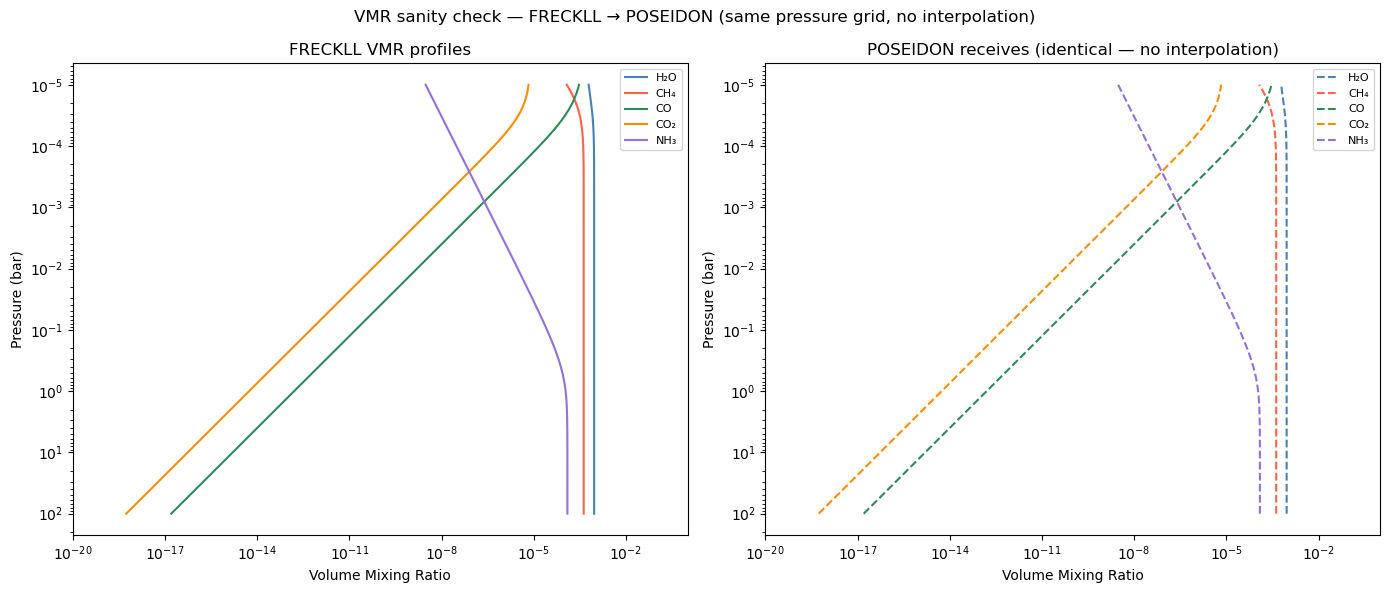

In [7]:
# Find a profile with clear vertical structure
example_data, example_row = None, None
for i in range(len(df_final_clean)):
    r = df_final_clean.iloc[i]
    d = np.load(r["path"])
    if d["h2o"].std() > 1e-10:
        example_data, example_row = d, r
        print(f"Using profile {i}: T={r['T']:.0f}K, log_Kzz={r['log_Kzz']:.1f}")
        break

molecules = [("h2o","H₂O","steelblue"), ("ch4","CH₄","tomato"),
             ("co","CO","seagreen"),     ("co2","CO₂","darkorange"),
             ("nh3","NH₃","mediumpurple")]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for mol, label, color in molecules:
    vmr = example_data[mol]   # linear, on FRECKLL grid
    # No interpolation — POSEIDON uses the same grid
    axes[0].plot(vmr, freckll_P, label=label, color=color, lw=1.5)
    axes[1].plot(vmr, P,         label=label, color=color, lw=1.5, linestyle="--")
    print(f"{label}: range {vmr.min():.2e} → {vmr.max():.2e}")

for ax, title in zip(axes, ["FRECKLL VMR profiles", "POSEIDON receives (identical — no interpolation)"]):
    ax.set_xscale("log"); ax.set_yscale("log"); ax.invert_yaxis()
    ax.set_xlabel("Volume Mixing Ratio"); ax.set_ylabel("Pressure (bar)")
    ax.set_xlim(1e-20, 1e0); ax.legend(fontsize=8); ax.set_title(title)

plt.suptitle("VMR sanity check — FRECKLL → POSEIDON (same pressure grid, no interpolation)", fontsize=12)
plt.tight_layout(); plt.show()

## 7. Full Spectrum Generation Loop

In [8]:
os.makedirs("disequil_spectra_kaggle", exist_ok=True)

# Checkpoint: skip already-computed spectra
already_done = set()
for fname in os.listdir("disequil_spectra_kaggle"):
    if fname.startswith("spectrum_") and fname.endswith(".npy"):
        already_done.add(fname.replace("spectrum_", "").replace(".npy", ""))

remaining_df = df_final_clean[~df_final_clean["uid"].isin(already_done)]
print(f"Already done : {len(already_done)}")
print(f"To process   : {len(remaining_df)}")

failed_uids = []

for row in tqdm(remaining_df.itertuples(), total=len(remaining_df), desc="Computing spectra"):
    uid = row.uid
    try:
        data = np.load(row.path)

        # Use getattr to avoid pandas .T transpose conflict
        T  = getattr(row, "T")
        Rp = getattr(row, "Rp_Rj")
        Mp = getattr(row, "Mp_Mj")

        T_input = np.full(N_layers, T)
        X_input = build_X_input(data["h2o"], data["ch4"],
                                 data["co"],  data["co2"], data["nh3"])

        R_p    = Rp * R_J
        M_p    = Mp * M_J
        planet = create_planet("freckll_planet", R_p, mass=M_p, T_eq=T)

        atmosphere = make_atmosphere(planet, model, P, 10.0, R_p,
                                      T_input=T_input, X_input=X_input)

        if not atmosphere["is_physical"]:
            print(f"[SKIP] Profile {uid} — atmosphere not physical "
                  f"(T={T:.0f}K, Rp={Rp:.2f}, Mp={Mp:.2f})")
            failed_uids.append(uid)
            continue

        spectrum_hires  = compute_spectrum(planet, star, model, atmosphere,
                                            opac, wl_highres,
                                            spectrum_type="transmission")
        spectrum_binned = spectres.spectres(wl_binned, wl_highres,
                                             spectrum_hires, verbose=False)

        if np.any(np.isnan(spectrum_binned)) or np.any(np.isinf(spectrum_binned)):
            print(f"[SKIP] Profile {uid} — NaN/Inf in spectrum")
            failed_uids.append(uid)
            continue

        np.save(f"disequil_spectra_kaggle/spectrum_{uid}.npy", spectrum_binned)

    except Exception as e:
        print(f"[ERROR] Profile {uid}: {e}")
        failed_uids.append(uid)
        continue

n_success = len(remaining_df) - len(failed_uids)
print(f"\nDone! Successful: {n_success}, Failed: {len(failed_uids)}")
print(f"Success rate: {100*n_success/max(len(remaining_df),1):.1f}%")

Already done : 0
To process   : 458


Computing spectra: 100%|██████████| 458/458 [02:43<00:00,  2.81it/s]


Done! Successful: 458, Failed: 0
Success rate: 100.0%


## 8. Collect Spectra and Save Arrays

In [9]:
spectra_list, params_list, uid_list = [], [], []

for fname in sorted(os.listdir("disequil_spectra_kaggle")):
    if not (fname.startswith("spectrum_") and fname.endswith(".npy")):
        continue
    uid   = fname[len("spectrum_"):-4]
    match = df_final_clean[df_final_clean["uid"] == uid]
    if match.empty:
        continue
    row = match.iloc[0]

    spec = np.load(os.path.join("disequil_spectra_kaggle", fname))
    spectra_list.append(spec)
    params_list.append([row["Rstar_Rs"], row["Rp_Rj"], row["Mp_Mj"],
                         row["T"], row["log_Kzz"]])
    uid_list.append(uid)

spectra_arr = np.array(spectra_list)
params_arr  = np.array(params_list)
full_arr    = np.hstack([spectra_arr, params_arr])

np.save("disequil_spectra_kaggle/disequil_spectra_kaggle.npy", spectra_arr)
np.save("disequil_spectra_kaggle/disequil_params_kaggle.npy",  params_arr)
np.save("disequil_spectra_kaggle/disequil_full_kaggle.npy",    full_arr)

print(f"Spectra shape : {spectra_arr.shape}")
print(f"Params shape  : {params_arr.shape}")
print(f"Full shape    : {full_arr.shape}")
print("Column order  : spectrum (52 bins) + [Rstar_Rs, Rp_Rj, Mp_Mj, T, log_Kzz]")

Spectra shape : (458, 52)
Params shape  : (458, 5)
Full shape    : (458, 57)
Column order  : spectrum (52 bins) + [Rstar_Rs, Rp_Rj, Mp_Mj, T, log_Kzz]


## 9. Plot Raw Spectra

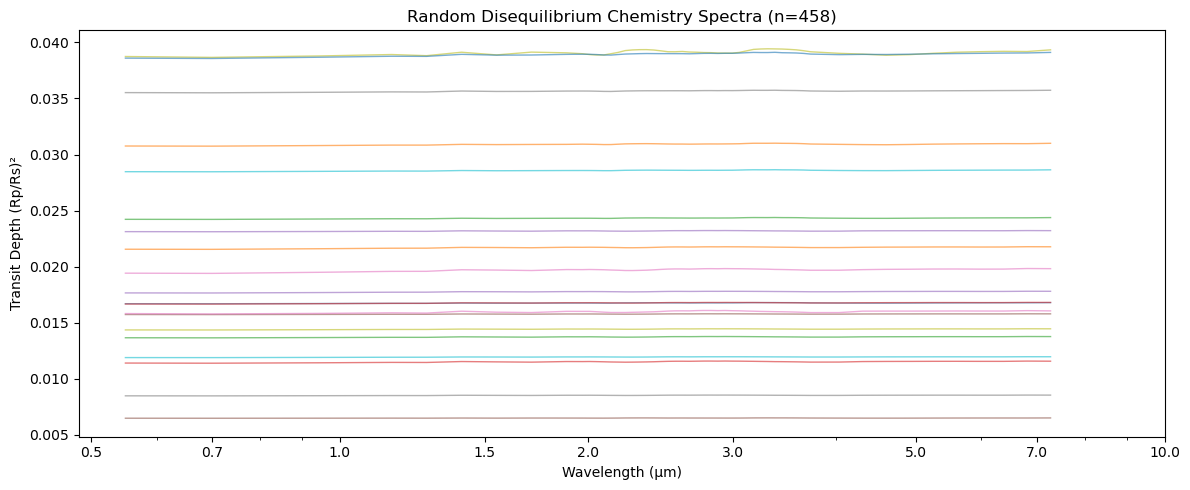

In [10]:
idx = np.random.choice(len(spectra_arr), min(20, len(spectra_arr)), replace=False)

fig, ax = plt.subplots(figsize=(12, 5))
for i in idx:
    ax.plot(wl_binned, spectra_arr[i], alpha=0.6, linewidth=1)

ax.set_xlabel("Wavelength (μm)")
ax.set_ylabel("Transit Depth (Rp/Rs)²")
ax.set_title(f"Random Disequilibrium Chemistry Spectra (n={len(spectra_arr)})")
ax.set_xscale("log")
ticks = [0.5, 0.7, 1.0, 1.5, 2.0, 3.0, 5.0, 7.0, 10.0]
ax.set_xticks(ticks); ax.set_xticklabels([str(t) for t in ticks])
ax.xaxis.set_minor_formatter(mticker.NullFormatter())
plt.tight_layout(); plt.show()

## 10. Row Z-Score Normalisation

Normalised spectra shape : (458, 52)
Mean (should be ~0)      : 0.0000
Std  (should be ~1)      : 0.9992


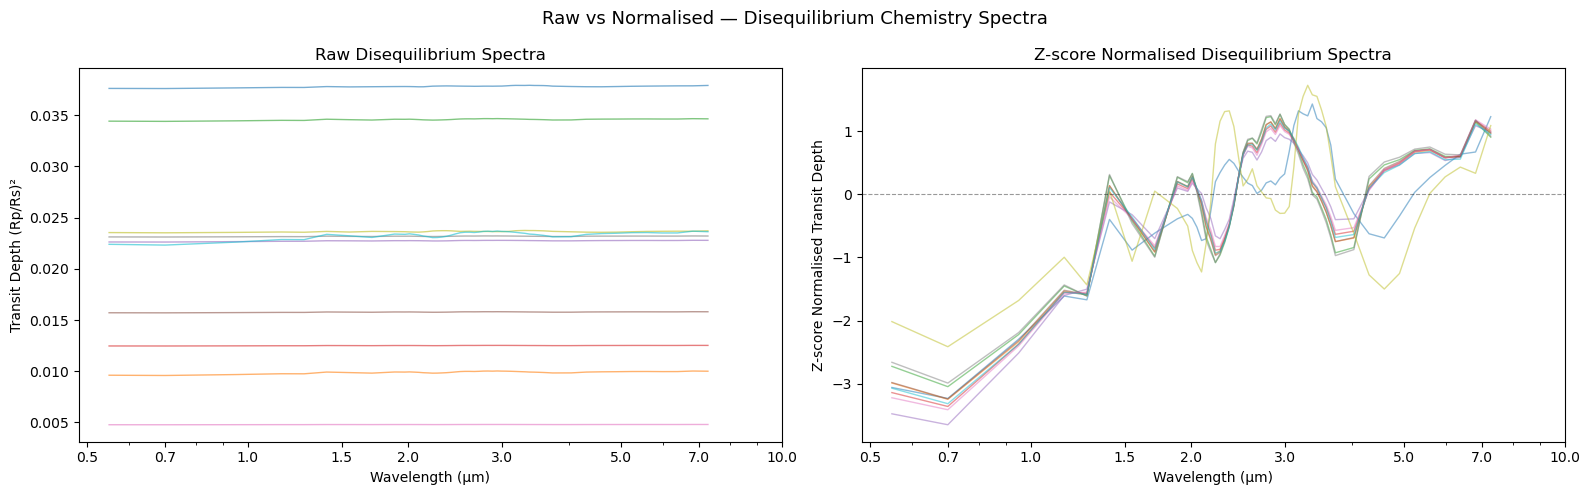

In [11]:
epsilon = 1e-8
spectra_mean = spectra_arr.mean(axis=1, keepdims=True)
spectra_std  = spectra_arr.std(axis=1, keepdims=True)
spectra_norm = (spectra_arr - spectra_mean) / (spectra_std + epsilon)

print(f"Normalised spectra shape : {spectra_norm.shape}")
print(f"Mean (should be ~0)      : {spectra_norm.mean():.4f}")
print(f"Std  (should be ~1)      : {spectra_norm.std():.4f}")

idx = np.random.choice(len(spectra_norm), min(10, len(spectra_norm)), replace=False)
ticks = [0.5, 0.7, 1.0, 1.5, 2.0, 3.0, 5.0, 7.0, 10.0]

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

for i in idx:
    axes[0].plot(wl_binned, spectra_arr[i],  alpha=0.6, lw=1)
    axes[1].plot(wl_binned, spectra_norm[i], alpha=0.5, lw=1)

axes[0].set_title("Raw Disequilibrium Spectra")
axes[0].set_ylabel("Transit Depth (Rp/Rs)²")

axes[1].set_title("Z-score Normalised Disequilibrium Spectra")
axes[1].set_ylabel("Z-score Normalised Transit Depth")
axes[1].axhline(0, color="black", lw=0.8, linestyle="--", alpha=0.4)

for ax in axes:
    ax.set_xlabel("Wavelength (μm)")
    ax.set_xscale("log")
    ax.set_xticks(ticks); ax.set_xticklabels([str(t) for t in ticks])
    ax.xaxis.set_minor_formatter(mticker.NullFormatter())

plt.suptitle("Raw vs Normalised — Disequilibrium Chemistry Spectra", fontsize=13)
plt.tight_layout(); plt.show()

## 11. Parameter Distributions

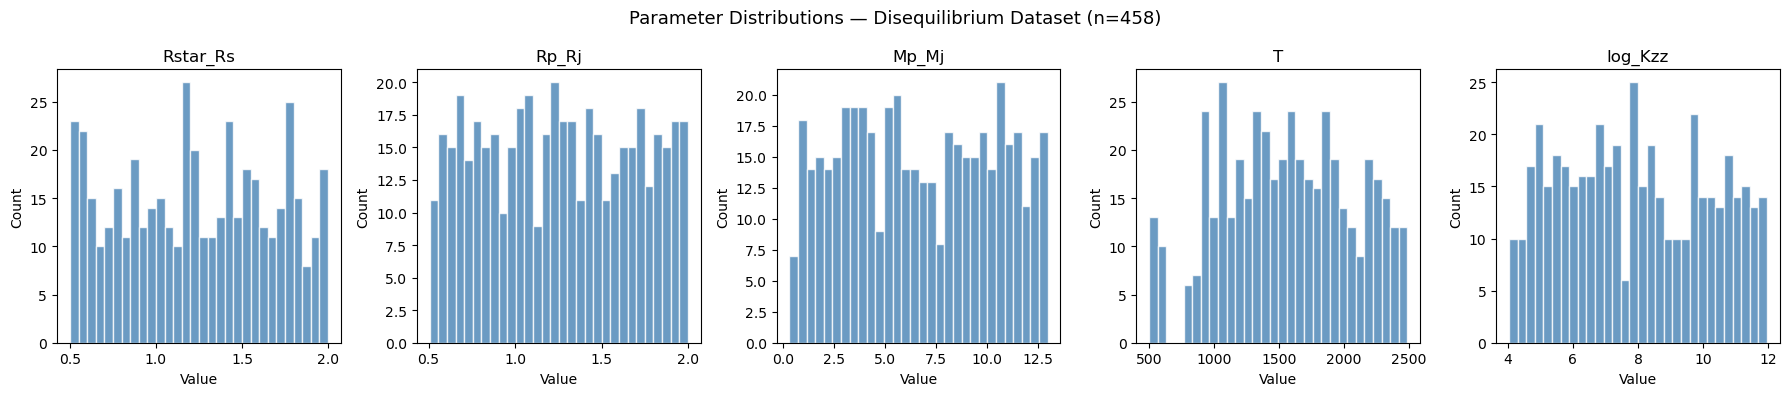

Parameter ranges in final dataset:
  Rstar_Rs: 0.501 → 1.998
  Rp_Rj: 0.506 → 1.997
  Mp_Mj: 0.308 → 12.979
  T: 500.229 → 2487.704
  log_Kzz: 4.039 → 11.967


In [12]:
param_names = ["Rstar_Rs", "Rp_Rj", "Mp_Mj", "T", "log_Kzz"]
fig, axes = plt.subplots(1, 5, figsize=(18, 4))

for i, (ax, name) in enumerate(zip(axes, param_names)):
    ax.hist(params_arr[:, i], bins=30, color="steelblue", alpha=0.8, edgecolor="white")
    ax.set_title(name); ax.set_xlabel("Value"); ax.set_ylabel("Count")

plt.suptitle(f"Parameter Distributions — Disequilibrium Dataset (n={len(params_arr)})", fontsize=13)
plt.tight_layout(); plt.show()

print("Parameter ranges in final dataset:")
for i, name in enumerate(param_names):
    print(f"  {name}: {params_arr[:, i].min():.3f} → {params_arr[:, i].max():.3f}")